In [1]:
import requests

def parse_web_page(url):
    """
    Fetch the content of the given web page.

    Args:
        url (str): The URL of the web page to fetch.

    Returns:
        str: The content of the page as a string.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    session = requests.Session()

    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:133.0) Gecko/20100101 Firefox/133.0',
        'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8',
        'Accept-Language': 'en-US,en;q=0.5',
        'Connection': 'keep-alive'
    }

    response = session.get(
        url,
        headers=headers,
        timeout=30
    )

    response.raise_for_status()

    return response.text

print(parse_web_page('https://en.wikipedia.org/wiki/Sirius_B')[:255])
print("------")
print(parse_web_page('https://www.chnu.edu.ua/novyny/aktualni-novyny/optyky-chnu-u-stenfordskomu-top-2-sviti/')[:255])

<!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clien
------
<!DOCTYPE html>
<html lang="uk" prefix="og: https://ogp.me/ns#">
<head>
    <meta charset="utf-8" />
    <meta name="viewport" content="width=device-width, initial-scale=1">
        <title>&#x41E;&#x43F;&#x442;&#x438;&#x43A;&#x438; &#x427;&#x41D;&#x4


In [2]:
import json

def parse_api(api_url):
    """
    Fetch the data of the given API endpoint and save it to result.json.

    Args:
        api_url (str): The URL of the API endpoint.

    Returns:
        None.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    response = requests.get(api_url)
    response.raise_for_status()

    data = response.json()

    with open('result.json', 'w', encoding='utf-8') as file:
        json.dump(data, file, indent=4, ensure_ascii=False)


"""
Replace the following api with api you wish to parse for this assignment.
You can use https://free-apis.github.io/#/ or any other available api endpoint you like.
"""
parse_api('https://api.github.com/')

In [4]:
import pandas as pd
def parse_json(date):
    with open('weather.json', 'r', encoding='utf-8') as file:
        data = json.load(file)

    target_date = pd.to_datetime(date).date()
    result = []

    def search_records(obj):
        if isinstance(obj, list):
            for item in obj:
                search_records(item)

        elif isinstance(obj, dict):
            if 'date' in obj:
                item_date = pd.to_datetime(obj['date']).date()

                if item_date == target_date:
                    result.append(obj)

            for value in obj.values():
                if isinstance(value, (dict, list)):
                    search_records(value)

    search_records(data)

    return result

target_date = '2024-8-19'
print(parse_json(target_date))

[{'date': '2024-08-19', 'max_temperature': 30.0, 'min_temperature': 21.0, 'precipitation': 5.0, 'wind_speed': 10.0, 'humidity': 70, 'weather_description': 'Light rain'}]


In [5]:
def parse_csv(date):
    """
    Parse the data from weather.csv file and return weather data for a given date.
    """
    df = pd.read_csv('weather.csv')

    
    date_column = "CET"

    # Перетворення дат
    df[date_column] = pd.to_datetime(
        df[date_column], errors='coerce'
    )

    target_date = pd.to_datetime(date).date()

    # Фільтрація за датою
    result = df[
        df[date_column].dt.date == target_date
    ]

    return result.to_dict(orient='records')


target_date = '1997-5-22'
print(parse_csv(target_date))

[{'CET': Timestamp('1997-05-22 00:00:00'), 'Max TemperatureC': 25.0, 'Mean TemperatureC': 18.0, 'Min TemperatureC': 10.0, 'Dew PointC': 11.0, 'MeanDew PointC': 8.0, 'Min DewpointC': 6.0, 'Max Humidity': 88.0, ' Mean Humidity': 54.0, ' Min Humidity': 34.0, ' Max Sea Level PressurehPa': 1017, ' Mean Sea Level PressurehPa': 1015, ' Min Sea Level PressurehPa': 1012, ' Max VisibilityKm': 10.0, ' Mean VisibilityKm': 10.0, ' Min VisibilitykM': 10.0, ' Max Wind SpeedKm/h': 11, ' Mean Wind SpeedKm/h': 3, ' Max Gust SpeedKm/h': nan, 'Precipitationmm': 0.0, ' CloudCover': 3.0, ' Events': nan, 'WindDirDegrees': 277}]


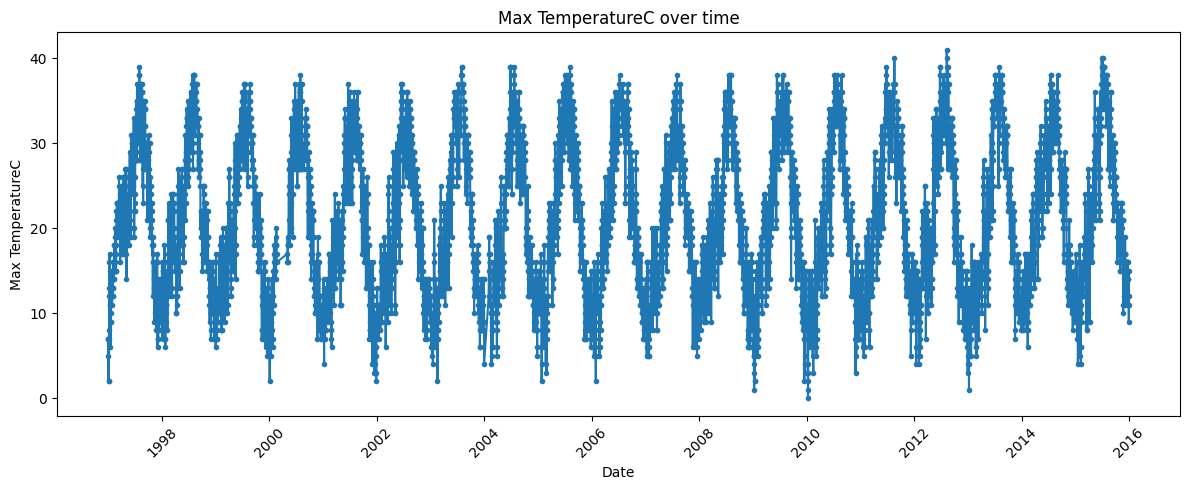

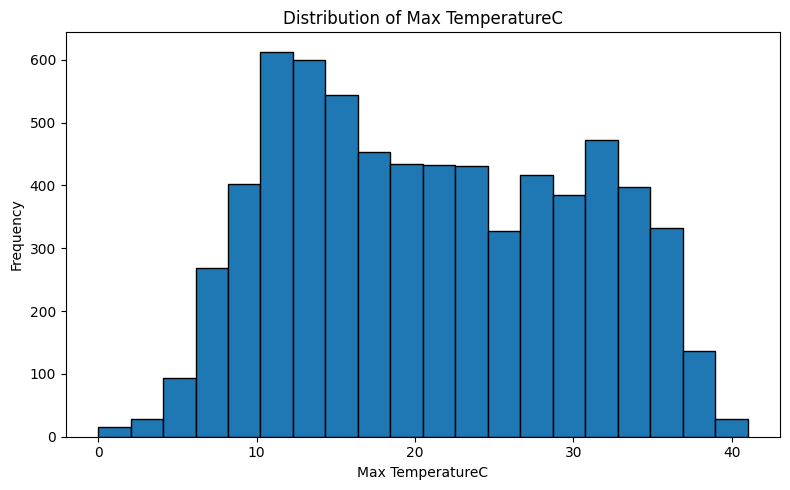

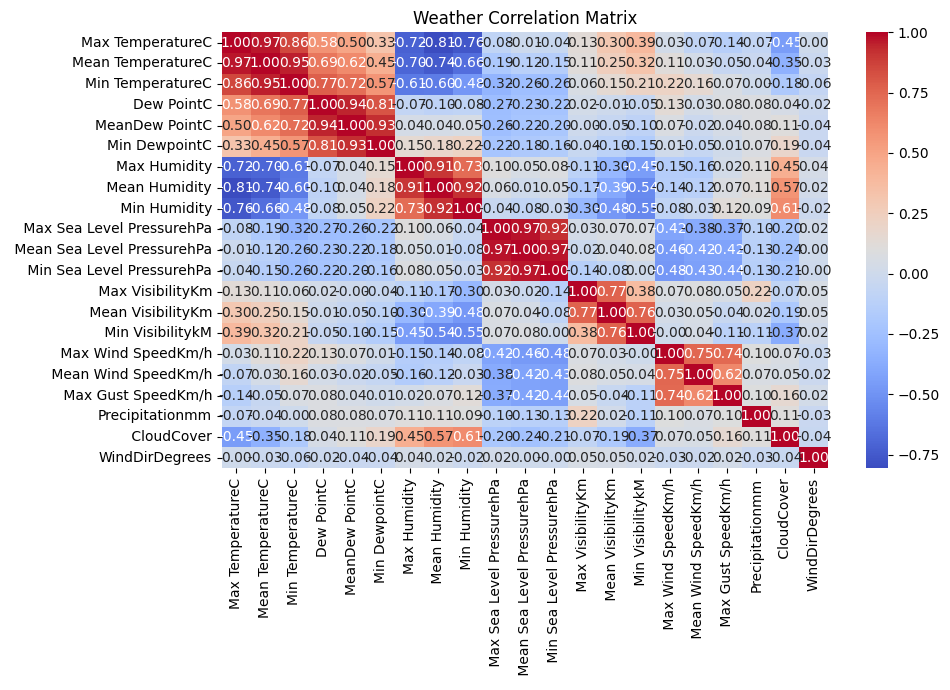

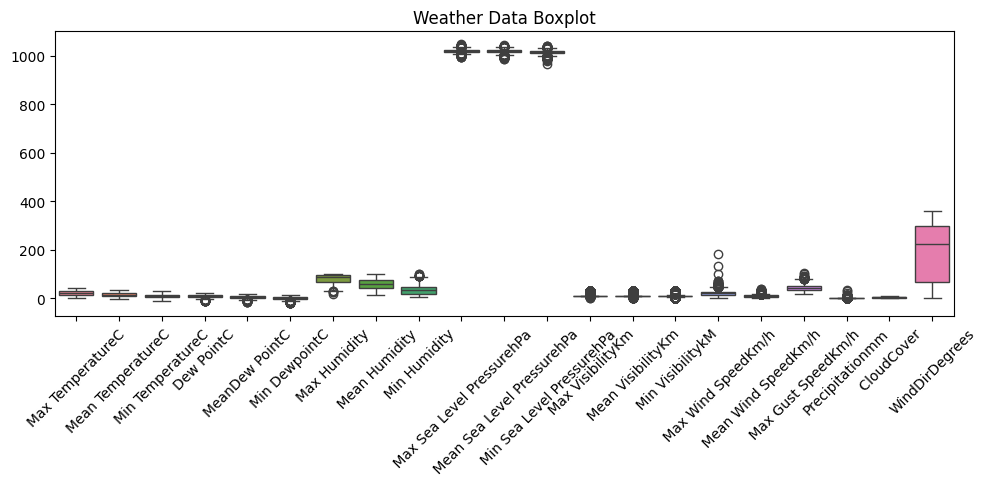

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
def visualize_weather_data():
    """
    Parse the data from weather.csv file and visualize it using Matplotlib.
    Save the results in the repository.
    """
    df = pd.read_csv('weather.csv')

    os.makedirs('results', exist_ok=True)

    
    date_col = "CET"

    if date_col:
        df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
        df = df.sort_values(date_col)

    numeric_df = df.select_dtypes(include=np.number)

    if numeric_df.empty:
        print("No numeric columns available for visualization.")
        return

    
    plt.figure(figsize=(12, 5))

    x = df[date_col] if date_col else df.index

    column = numeric_df.columns[0]
    plt.plot(x, df[column], marker='o', markersize=3)

    plt.title(f'{column} over time')
    plt.xlabel('Date' if date_col else 'Observation')
    plt.ylabel(column)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('results/weather_time_series.png')
    plt.show()

    # 2. Гістограма
    plt.figure(figsize=(8, 5))
    plt.hist(numeric_df[column].dropna(), bins=20, edgecolor='black')
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.savefig('results/weather_histogram.png')
    plt.show()

    # 3. Кореляційна матриця
    if numeric_df.shape[1] >= 2:
        plt.figure(figsize=(10, 7))
        sns.heatmap(
            numeric_df.corr(),
            annot=True,
            cmap='coolwarm',
            fmt='.2f'
        )
        plt.title('Weather Correlation Matrix')
        plt.tight_layout()
        plt.savefig('results/weather_correlation.png')
        plt.show()

    # 4. Діаграма розмаху
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=numeric_df)
    plt.title('Weather Data Boxplot')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('results/weather_boxplot.png')
    plt.show()


visualize_weather_data()

   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtyp

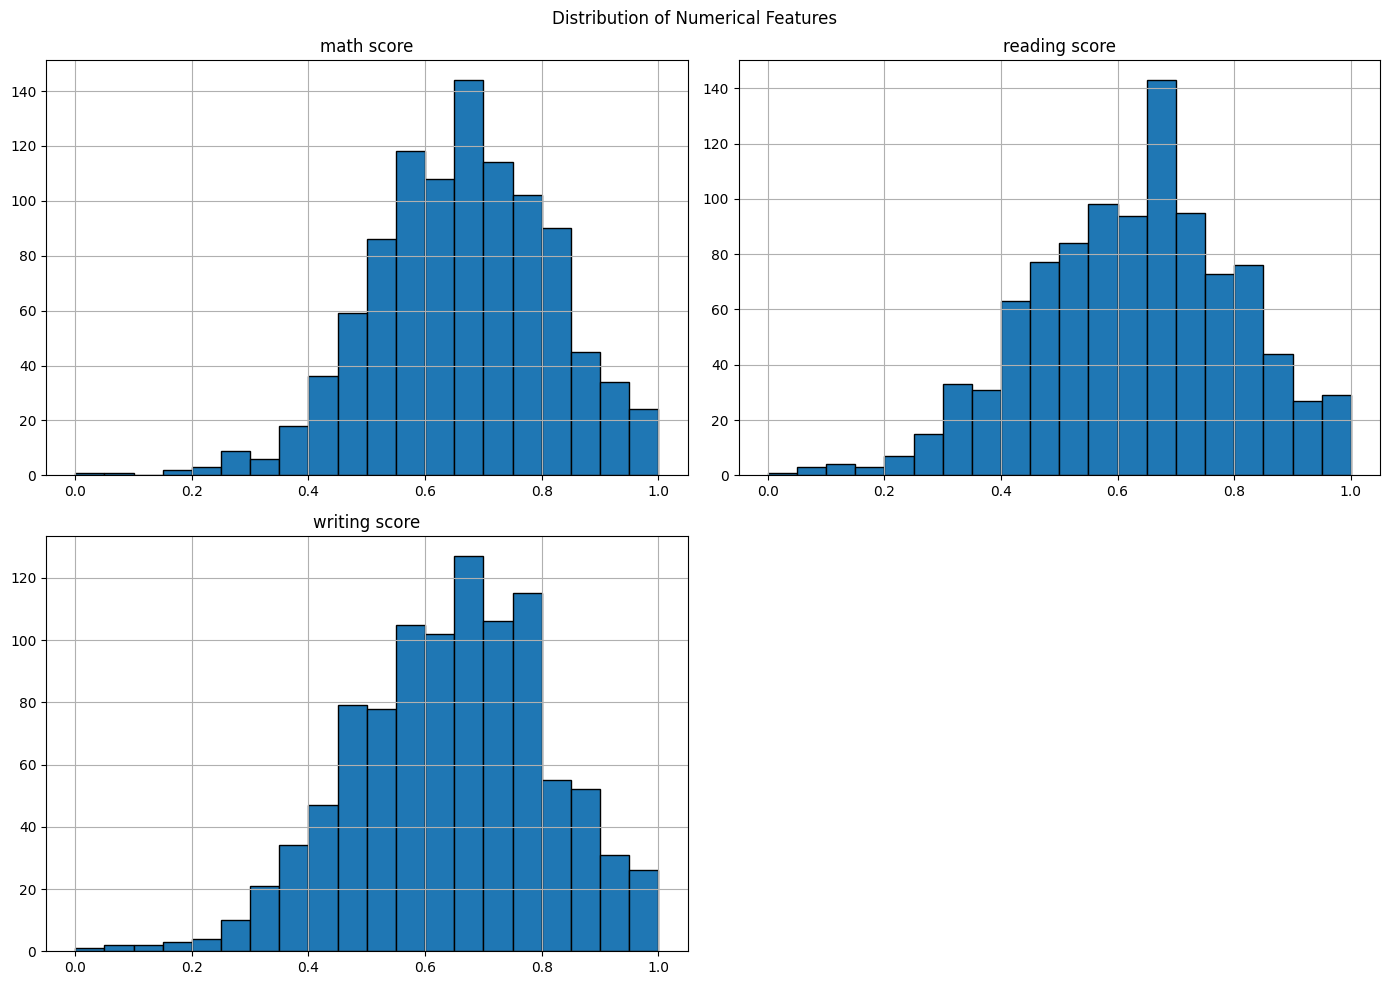

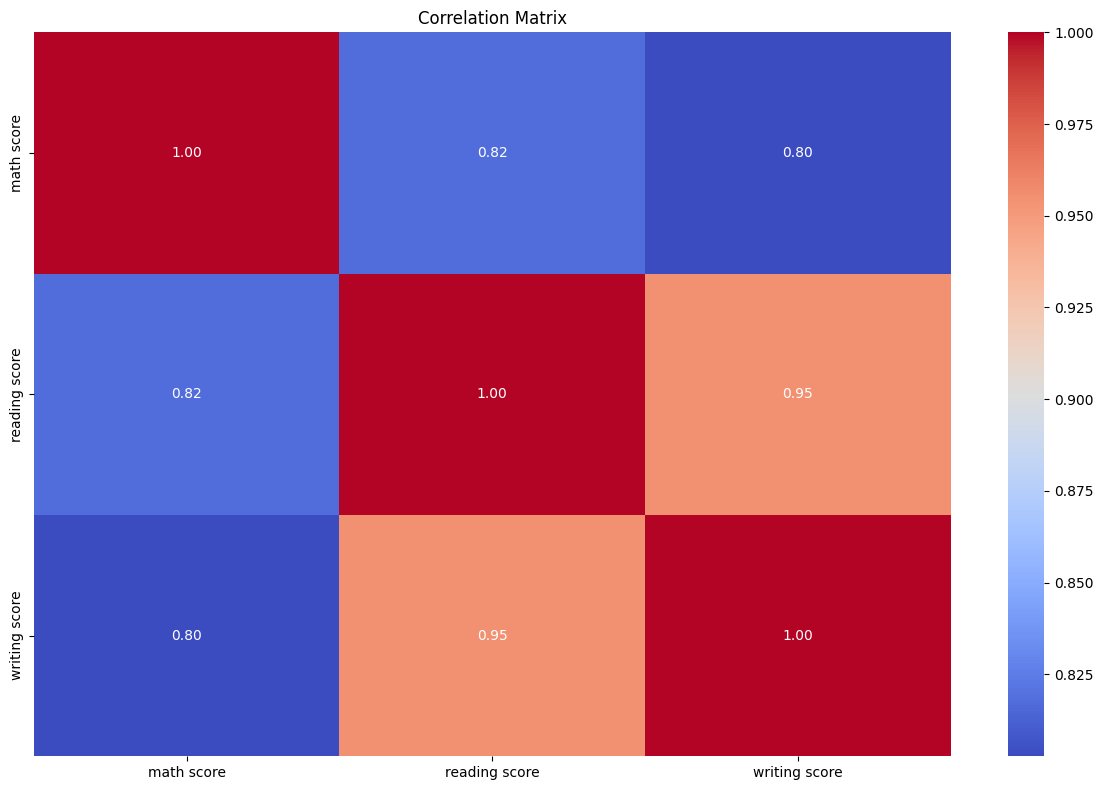

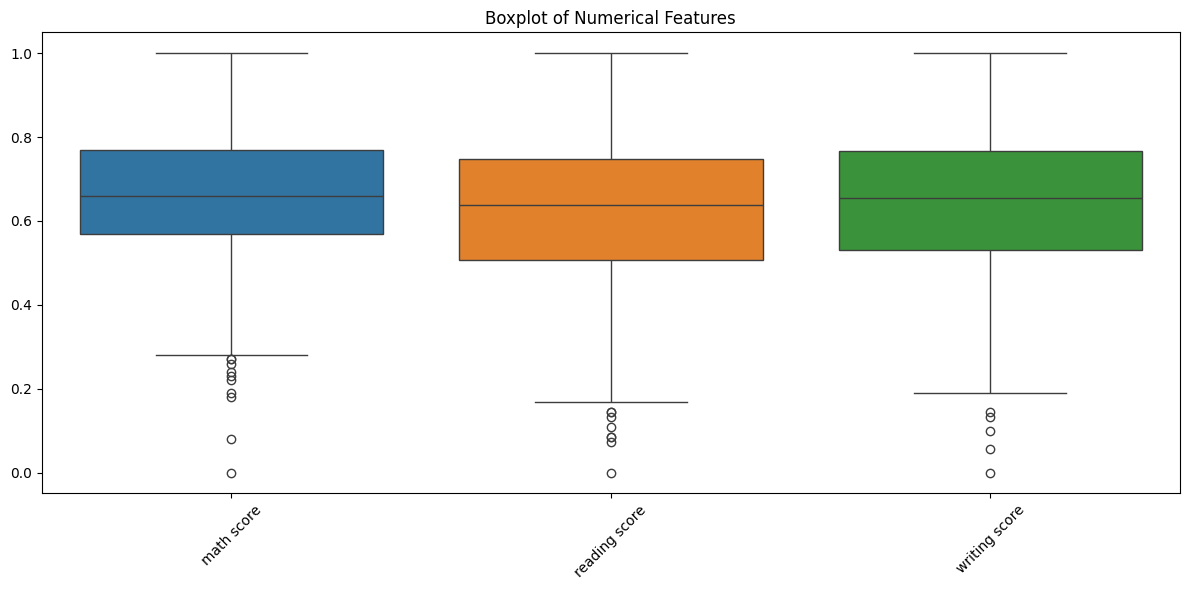

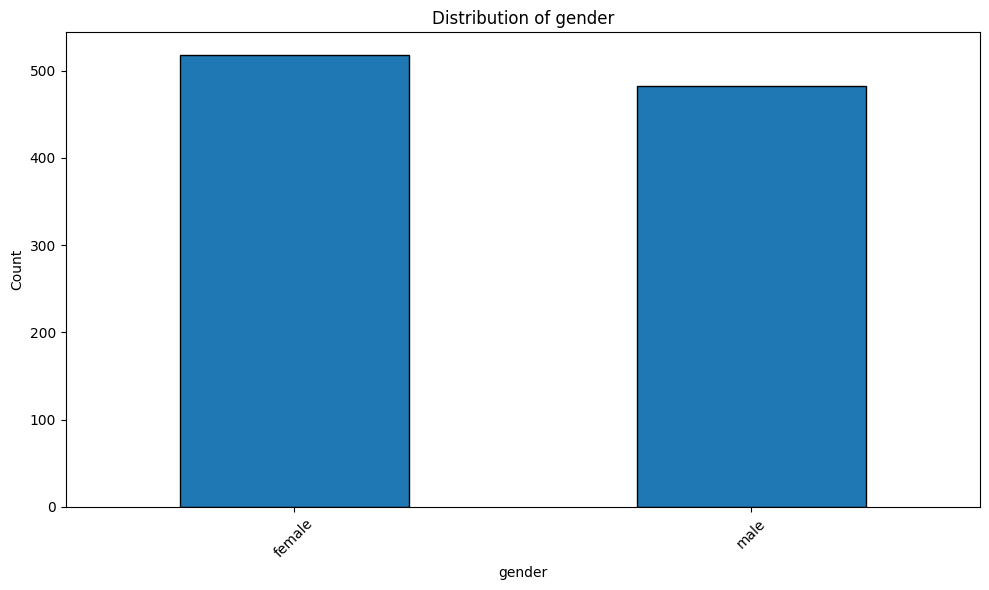

All visualizations have been saved in the results folder.


In [15]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler

# # import kagglehub
# # from kagglehub import KaggleDatasetAdapter

# def load_dataset(url, csv_file):
#     """
#     Load the dataset from Kaggle using kagglehub.
#     """
#     df = kagglehub.dataset_load(
#         KaggleDatasetAdapter.PANDAS,
#         url,
#         csv_file
#     )
#     return df


# df = load_dataset(
#     'ilayaraja07/data-cleaning-feature-imputation',
#     'Students_Performance_knn.csv'
# )

df=pd.read_csv('Students_Performance_knn.csv')

print(df.head())
print(df.info())
print(df.isnull().sum())


def impute_data(df):
    """
    Parse the data from file and impute missing values.
    """
    df = df.copy()

    # Видаляємо стовпці, які повністю складаються з пропусків
    empty_columns = df.columns[df.isnull().all()]
    df = df.drop(columns=empty_columns)

    # Визначаємо числові та категоріальні стовпці
    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns

    categorical_columns = df.select_dtypes(
        exclude=np.number
    ).columns

    # Заповнення числових пропусків медіаною
    if len(numeric_columns) > 0:
        numeric_imputer = SimpleImputer(strategy='median')
        df[numeric_columns] = numeric_imputer.fit_transform(
            df[numeric_columns]
        )

    # Заповнення категоріальних пропусків модою
    if len(categorical_columns) > 0:
        categorical_imputer = SimpleImputer(
            strategy='most_frequent'
        )
        df[categorical_columns] = categorical_imputer.fit_transform(
            df[categorical_columns]
        )

    print("Missing values after imputation:")
    print(df.isnull().sum())

    return df


def normalize_data(df):
    """
    Normalize the data using MinMaxScaler.
    """
    df = df.copy()

    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns

    if len(numeric_columns) > 0:
        scaler = MinMaxScaler()

        df[numeric_columns] = scaler.fit_transform(
            df[numeric_columns]
        )

    print("Data normalization completed.")

    return df


def visualize_data(df):
    """
    Visualize the data using Matplotlib.
    Save the results in the repository.
    """
    os.makedirs('results', exist_ok=True)

    numeric_df = df.select_dtypes(include=np.number)
    categorical_df = df.select_dtypes(exclude=np.number)

    # 1. Гістограми числових ознак
    if not numeric_df.empty:
        numeric_df.hist(
            figsize=(14, 10),
            bins=20,
            edgecolor='black'
        )

        plt.suptitle('Distribution of Numerical Features')
        plt.tight_layout()
        plt.savefig('results/numerical_distributions.png')
        plt.show()

        # 2. Кореляційна матриця
        if numeric_df.shape[1] >= 2:
            plt.figure(figsize=(12, 8))

            sns.heatmap(
                numeric_df.corr(),
                annot=True,
                cmap='coolwarm',
                fmt='.2f'
            )

            plt.title('Correlation Matrix')
            plt.tight_layout()
            plt.savefig('results/correlation_matrix.png')
            plt.show()

        # 3. Boxplot
        plt.figure(figsize=(12, 6))

        sns.boxplot(data=numeric_df)

        plt.title('Boxplot of Numerical Features')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig('results/numerical_boxplot.png')
        plt.show()

    # 4. Категоріальні ознаки
    if not categorical_df.empty:
        column = categorical_df.columns[0]

        plt.figure(figsize=(10, 6))

        categorical_df[column].value_counts().head(10).plot(
            kind='bar',
            edgecolor='black'
        )

        plt.title(f'Distribution of {column}')
        plt.xlabel(column)
        plt.ylabel('Count')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig('results/categorical_distribution.png')
        plt.show()

    print("All visualizations have been saved in the results folder.")

df = df=pd.read_csv('Students_Performance_knn.csv')
df = impute_data(df)
df = normalize_data(df)
visualize_data(df)